## 1. Data Acquisition / Data Cleaning

In [1]:
# ..............................................................
# VANGUARD A/B TEST – DAY 1 & 2 (SIMPLE VERSION)
# ................................................................

# The 3 datasets (linked by client_id):
#   1. df_final_demo                -> WHO is the client (age, gender, tenure, balance...)
#   2. df_final_experiment_clients  -> WHICH website: Test = new, Control = old
#   3. df_final_web_data pt_1 + pt_2 -> WHAT they clicked, 1 row = 1 click
#      pages: start -> step_1 -> step_2 -> step_3 -> confirm
#      reaching "confirm" = the client FINISHED
#
# ............................................................................
# Main question: do more clients reach "confirm" with the new website?

In [46]:
# ..............................................................
# STEP 1 – IMPORT LIBRARIES
# ..............................................................
# pandas = tables | matplotlib + seaborn = charts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

%matplotlib inline

In [3]:
# ..............................................................
# STEP 2 – LOAD THE DATA FROM GITHUB
# ..............................................................

# pd.read_csv reads a file and turns it into a table (DataFrame)

PATH = "https://raw.githubusercontent.com/data-bootcamp-v4/lessons/main/5_6_eda_inf_stats_tableau/project/files_for_project/"

df_demo = pd.read_csv(PATH + "df_final_demo.txt")
df_experiment = pd.read_csv(PATH + "df_final_experiment_clients.txt")
df_web_pt1 = pd.read_csv(PATH + "df_final_web_data_pt_1.txt")
df_web_pt2 = pd.read_csv(PATH + "df_final_web_data_pt_2.txt")

In [4]:
# ..............................................................
# STEP 3 – FIRST LOOK
# ..............................................................
# .head() = first 5 rows

df_demo.head(30)  # WHO is the client (age, gender, tenure, balance...)

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0
5,3727881,5.0,71.0,30.5,U,2.0,23915.60,0.0,3.0
6,272934,5.0,66.0,58.5,U,2.0,27021.42,2.0,5.0
7,388801,30.0,361.0,57.5,M,5.0,522498.72,1.0,4.0
8,285619,30.0,369.0,67.5,M,2.0,299388.72,3.0,6.0
9,8198645,15.0,189.0,54.5,F,2.0,382303.83,6.0,9.0


In [5]:
df_experiment.head(30)  # WHICH website: Test = new, Control = old

,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control
5,9466803,Test
6,3170143,Test
7,6651403,Control
8,5887227,Test
9,2105948,Control


In [6]:
df_web_pt1.head(30)  # WHAT they clicked, 1 row = 1 click

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04
5,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:17:15
6,9988021,580560515_7732621733,781255054_21935453173_531117,step_1,2017-04-17 15:17:01
7,9988021,580560515_7732621733,781255054_21935453173_531117,start,2017-04-17 15:16:22
8,8320017,39393514_33118319366,960651974_70596002104_312201,confirm,2017-04-05 13:10:05
9,8320017,39393514_33118319366,960651974_70596002104_312201,step_3,2017-04-05 13:09:43


In [7]:
# ..............................................................
# STEP 4 – CLEAN THE WEB DATA
# ..............................................................
# 1. pd.concat     = put part 2 under part 1
# 2. drop_duplicates = remove clicks recorded twice
# 3. pd.to_datetime  = turn the date text into a real date

df_web = pd.concat([df_web_pt1, df_web_pt2], ignore_index=True)
print("duplicates:", df_web.duplicated().sum())

df_web = df_web.drop_duplicates()
df_web["date_time"] = pd.to_datetime(df_web["date_time"])

print("rows after cleaning:", len(df_web))

duplicates: 10764
rows after cleaning: 744641


In [8]:
# ..............................................................
# STEP 5 – CLEAN THE EXPERIMENT DATA
# ..............................................................
# Clients with an empty Variation were not in the test -> remove them with dropna

print(df_experiment["Variation"].value_counts(dropna=False))

df_experiment = df_experiment.dropna()
print("clients in the test:", len(df_experiment))

Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64
clients in the test: 50500


In [9]:
# ..............................................................
# STEP 6 – CLEAN THE CLIENT PROFILES
# ..............................................................
# 1. dropna  = remove the 15 clients with missing information
# 2. replace = gender 'X' (only 3 people) becomes 'U' (unknown)

print(df_demo.isna().sum())

df_demo = df_demo.dropna()
df_demo["gendr"] = df_demo["gendr"].replace("X", "U")

print("clients left:", len(df_demo))

client_id            0
clnt_tenure_yr      14
clnt_tenure_mnth    14
clnt_age            15
gendr               14
num_accts           14
bal                 14
calls_6_mnth        14
logons_6_mnth       14
dtype: int64
clients left: 70594


In [10]:
# ..............................................................
# STEP 7 – MERGE THE TABLES
# ..............................................................
# merge = join 2 tables using client_id (like VLOOKUP in Excel)
#   clients = 1 row per client (group + profile)
#   df      = 1 row per click (with the client's group)

clients = df_experiment.merge(df_demo, on="client_id")
df = df_web.merge(df_experiment, on="client_id")

print("clients:", clients.shape)
print("clicks :", df.shape)

clients: (50487, 10)
clicks : (317235, 6)


In [11]:
# ..............................................................
# STEP 8 – EXPLORE THE DATA
# ..............................................................
# describe = count, mean, min, max of each column
# round(1) = keep 1 decimal so it is easier to read

clients.describe().round(1)

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,num_accts,bal,calls_6_mnth,logons_6_mnth
count,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0
mean,5006179.8,12.0,150.4,47.3,2.3,149516.8,3.1,6.1
std,2877444.9,6.9,81.9,15.5,0.5,302039.0,2.2,2.2
min,555.0,2.0,33.0,17.0,1.0,23789.4,0.0,3.0
25%,2515688.0,6.0,82.0,33.5,2.0,39877.2,1.0,4.0
50%,5025043.0,11.0,136.0,48.0,2.0,65734.3,3.0,6.0
75%,7477922.0,16.0,192.0,59.5,2.0,139958.3,5.0,8.0
max,9999832.0,55.0,669.0,96.0,7.0,16320040.2,6.0,9.0


In [12]:
# INTERPRETATION: we are checking for odd values

# On average, clients have been with Vanguard for 12 years.
# The newest client has been there 2 years, the oldest 55 years.
# Half the clients have been there 11 years or less.

# we can already see that clients are about 48 years old and have been with Vanguard about 11 years.

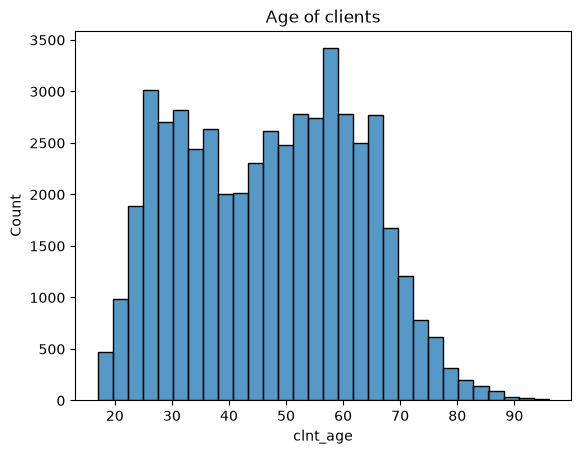

median age: 48.0


In [13]:
# ..............................................................
# STEP 9 – WHO ARE THE CLIENTS?
# ..............................................................
# 9.1 AGE

sns.histplot(clients["clnt_age"], bins=30)
plt.title("Age of clients")
plt.show()

print("median age:", clients["clnt_age"].median())

In [14]:
# 9.2 AGE GROUPS

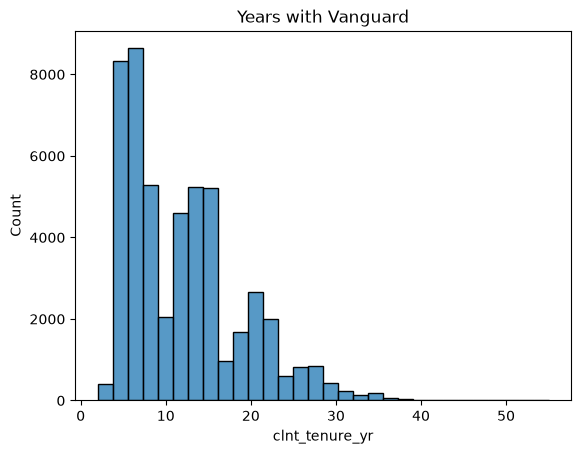

median tenure: 11.0 years
clients with less than 5 years: 7.5 %


In [15]:
# 9.3 TENURE (years with Vanguard)

sns.histplot(clients["clnt_tenure_yr"], bins=30)
plt.title("Years with Vanguard")
plt.show()

print("median tenure:", clients["clnt_tenure_yr"].median(), "years")
print(
    "clients with less than 5 years:",
    round((clients["clnt_tenure_yr"] < 5).mean() * 100, 1),
    "%",
)

# clients['clnt_tenure_yr'] < 5 checks each client and gives True if they have been with Vanguard less than 5 years, False otherwise.
# .mean() gives the share of True. Python counts True as 1 and False as 0

In [16]:
# 9.4 GENDER

clients["gendr"].value_counts(normalize=True).round(2)

gendr
U    0.34
M    0.34
F    0.32
Name: proportion, dtype: float64

In [17]:
# ANSWER
# Clients are rather OLDER: median age 48, the biggest group seems to be 50-59
# Clients are LONG-STANDING: median 11 years with Vanguard,
#   only 7.5% have less than 5 years
#  Gender is split in 3 almost equal parts (M / F / U)

In [18]:
# ..............................................................
# STEP 10 – CLIENT BEHAVIOUR
# ..............................................................
# 10.1 How many clients finished the process (reached 'confirm')?

finished = df[df["process_step"] == "confirm"]["client_id"].unique()
clients["completed"] = clients["client_id"].isin(finished)

print("clients who finished:", round(clients["completed"].mean() * 100, 1), "%")

clients who finished: 67.6 %


In [19]:
# 10.2 Who finishes the most? (by age group)

In [20]:
# 10.3 How many visits per client?

visits = df.groupby("client_id")["visit_id"].nunique()
visits.value_counts().head(30)

visit_id
1     37504
2      9450
3      2311
4       714
5       263
6       105
7        59
8        38
9        24
10       12
12        8
11        4
13        4
14        1
17        1
15        1
18        1
Name: count, dtype: int64

In [21]:
# ANSWER
# 68% of clients finished the process
# Older clients finish less: 70+ only 57% vs 69% for under 30
# Most clients (74%) did the process in only 1 visit

In [22]:
# ..............................................................
# STEP 11 – ARE TEST AND CONTROL SIMILAR?
# ..............................................................
# If both groups have the same profile, the comparison is fair
# We want to know whether the new website makes more people finish. That’s only fair if the Test and Control groups are similar.

clients.groupby("Variation")[["clnt_age", "clnt_tenure_yr", "bal"]].mean().round(1)

,clnt_age,clnt_tenure_yr,bal
Variation,,,
Control,47.5,12.1,150151.9
Test,47.2,12.0,148962.6


In [23]:
# ANSWER
# The two groups are almost the same (age 47.5 vs 47.2, tenure 12.1 vs 12.0)
# So the comparison between the old and new website is fair

In [24]:
# ..............................................................
# STEP 12 – SAVE THE CLEAN DATA
# ..............................................................
# to_csv saves the tables for Day 3 and Tableau

df.to_csv("df_clean.csv", index=False)
clients.to_csv("df_clients.csv", index=False)

# 2. KPIs and Metrics

## Time Spent on Each Process Step

### Objective

The goal is to compare how much time clients spend on each step of the online process in the Test and Control groups. This helps us understand whether the new design makes the process faster or whether clients experience delays at specific steps.

### Approach

We will use the timestamps recorded for each client's website activity to calculate the time spent on each process step, then compare the results between the two experiment groups.

In [25]:
# Check the columns and first few rows of the web activity dataset
display(df_web.head())

# Check the columns and first few rows of the experiment assignments
display(df_experiment.head())

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


## Prepare Data for Time Calculation

Before calculating the time between process steps, we need to sort the website activity records chronologically for each client and visit. This is important because the original dataset is not necessarily ordered by timestamp.

In [26]:
# Create a copy so we don't modify the original web activity dataset
df_time = df_web.copy()

# Sort events chronologically within each client's visit
df_time = df_time.sort_values(by=["client_id", "visit_id", "date_time"])

# Display the first rows to check the chronological order
display(df_time.head(10))

,client_id,visitor_id,visit_id,process_step,date_time
285515,169,201385055_71273495308,749567106_99161211863_557568,start,2017-04-12 20:19:36
285514,169,201385055_71273495308,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
285513,169,201385055_71273495308,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
285512,169,201385055_71273495308,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
285511,169,201385055_71273495308,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
628456,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:26:55
628331,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:42:43
442857,546,475037402_89828530214,731811517_9330176838_94847,start,2017-06-17 10:03:29
442856,546,475037402_89828530214,731811517_9330176838_94847,step_1,2017-06-17 10:03:39
442855,546,475037402_89828530214,731811517_9330176838_94847,step_2,2017-06-17 10:03:52


## 2.3. Calculate Time Between Process Events

We calculate the time difference between consecutive website events for each client and visit. This gives us the elapsed time between recorded events, which we can use to investigate how long clients take to progress through the process.

Repeated steps and unusually long time intervals must be considered when interpreting the results.

In [27]:
# Group events by client and visit, then find the next event timestamp
df_time["next_date_time"] = df_time.groupby(["client_id", "visit_id"])[
    "date_time"
].shift(-1)

# Calculate the time in seconds between each event and the next one
df_time["time_seconds"] = (
    df_time["next_date_time"] - df_time["date_time"]
).dt.total_seconds()

# Display the events and their calculated time differences
display(
    df_time[
        [
            "client_id",
            "visit_id",
            "process_step",
            "date_time",
            "next_date_time",
            "time_seconds",
        ]
    ].head(10)
)

,client_id,visit_id,process_step,date_time,next_date_time,time_seconds
285515,169,749567106_99161211863_557568,start,2017-04-12 20:19:36,2017-04-12 20:19:45,9.0
285514,169,749567106_99161211863_557568,step_1,2017-04-12 20:19:45,2017-04-12 20:20:31,46.0
285513,169,749567106_99161211863_557568,step_2,2017-04-12 20:20:31,2017-04-12 20:22:05,94.0
285512,169,749567106_99161211863_557568,step_3,2017-04-12 20:22:05,2017-04-12 20:23:09,64.0
285511,169,749567106_99161211863_557568,confirm,2017-04-12 20:23:09,NaT,NaN
628456,336,649044751_80905125055_554468,start,2017-06-01 07:26:55,2017-06-01 07:42:43,948.0
628331,336,649044751_80905125055_554468,start,2017-06-01 07:42:43,NaT,NaN
442857,546,731811517_9330176838_94847,start,2017-06-17 10:03:29,2017-06-17 10:03:39,10.0
442856,546,731811517_9330176838_94847,step_1,2017-06-17 10:03:39,2017-06-17 10:03:52,13.0
442855,546,731811517_9330176838_94847,step_2,2017-06-17 10:03:52,2017-06-17 10:05:19,87.0


In [28]:
# Keep intervals that have a following event and a valid time difference
df_step_time = df_time.dropna(subset=["next_date_time", "time_seconds"]).copy()

# Check how many intervals are negative or zero
print("Zero or negative intervals:", (df_step_time["time_seconds"] <= 0).sum())

# Summarise the time intervals for each process step
step_time_summary = (
    df_step_time.groupby("process_step")["time_seconds"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(1)
)

# Display the summary statistics in seconds
display(step_time_summary)

Zero or negative intervals: 953


,count,mean,median,min,max
process_step,,,,,
confirm,13634,256.9,76.0,0.0,35680.0
start,192763,61.3,15.0,0.0,40235.0
step_1,149164,60.5,26.0,0.0,10286.0
step_2,126809,92.6,63.0,0.0,21763.0
step_3,103159,132.8,61.0,0.0,17052.0


In [29]:
# Count how many recorded intervals exceed five minutes (300 seconds)
long_intervals = df_step_time[df_step_time["time_seconds"] > 300]

print("Intervals longer than 5 minutes:", len(long_intervals))
print(
    "Percentage of all intervals:",
    round(len(long_intervals) / len(df_step_time) * 100, 2),
    "%",
)

# Check how these long intervals are distributed across process steps
display(
    long_intervals.groupby("process_step")["time_seconds"]
    .agg(["count", "median", "max"])
    .round(1)
)

Intervals longer than 5 minutes: 30316
Percentage of all intervals: 5.18 %


,count,median,max
process_step,,,
confirm,2978,964.0,35680.0
start,7365,542.0,40235.0
step_1,4830,456.0,10286.0
step_2,4679,434.0,21763.0
step_3,10464,504.5,17052.0


In [30]:
# Add each client's Test or Control assignment to the interval data
df_step_time = df_step_time.merge(
    df_experiment[["client_id", "Variation"]], on="client_id", how="inner"
)

# Check that both experiment groups are present
print(df_step_time["Variation"].value_counts())

Variation
Test       139495
Control    108293
Name: count, dtype: int64


In [31]:
# Compare elapsed time between recorded events for Test and Control
step_time_comparison = (
    df_step_time.groupby(["process_step", "Variation"])["time_seconds"]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the results for each process step and experiment group
display(step_time_comparison)

count   mean  median
process_step Variation                      
confirm      Control     1920  168.7    46.0
             Test        4089  243.7    93.0
start        Control    35737   66.8    20.0
             Test       46323   61.5    14.0
step_1       Control    26043   50.5    20.0
             Test       35527   60.7    27.0
step_2       Control    24313   92.0    64.0
             Test       29573   88.8    61.0
step_3       Control    20280  137.1    72.0
             Test       23983  129.6    58.0

In [32]:
# Identify the process step recorded immediately after each event
df_time["next_process_step"] = df_time.groupby(["client_id", "visit_id"])[
    "process_step"
].shift(-1)

# Check which events follow a confirm event within the same visit
confirm_following = df_time.loc[
    df_time["process_step"] == "confirm", "next_process_step"
].value_counts(dropna=False)

# Display the next recorded steps after confirm
display(confirm_following)

next_process_step
NaN        88872
confirm    11772
start       1109
step_1       552
step_3       194
step_2         7
Name: count, dtype: int64

In [33]:
# Keep the four main process steps for the primary time comparison
main_steps = df_step_time[
    df_step_time["process_step"].isin(["start", "step_1", "step_2", "step_3"])
].copy()

# Calculate the median elapsed time for each step and experiment group
main_step_comparison = (
    main_steps.groupby(["process_step", "Variation"])["time_seconds"].median().unstack()
)

# Calculate the difference between Test and Control in seconds
main_step_comparison["Test - Control (seconds)"] = (
    main_step_comparison["Test"] - main_step_comparison["Control"]
)

# Display the results
display(main_step_comparison)

Variation,Control,Test,Test - Control (seconds)
process_step,,,
start,20.0,14.0,-6.0
step_1,20.0,27.0,7.0
step_2,64.0,61.0,-3.0
step_3,72.0,58.0,-14.0


### Visualization: Median Time per Step

This chart compares the median elapsed time between recorded events for the Control and Test groups at each process step. It helps identify which steps were faster or slower with the new design.

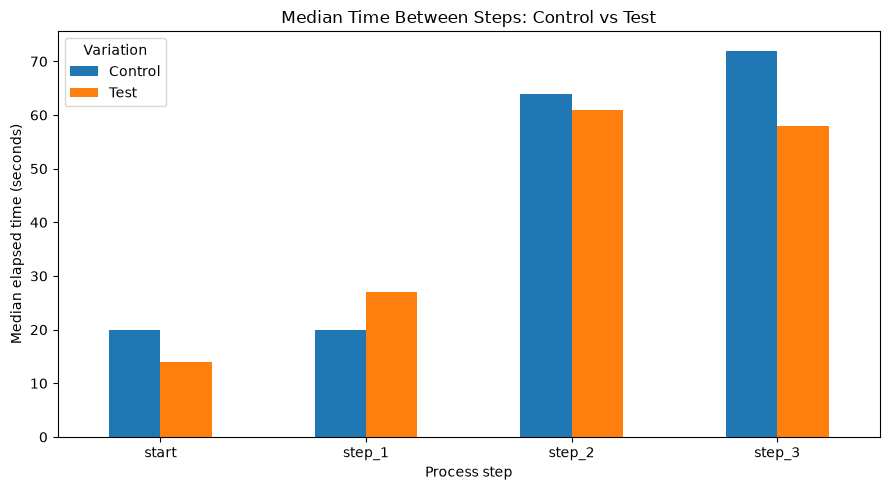

In [ ]:
# Compare median elapsed time per step between Control and Test
main_step_comparison[["Control", "Test"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylabel="Median elapsed time (seconds)",
    xlabel="Process step",
    title="Median Time Between Steps: Control vs Test",
)

# Display the chart with readable labels
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Findings: Time Between Process Steps

The Test group had lower median elapsed times at three of the four main process steps.

- **Start:** The Test group had a median 6 seconds lower than Control.
- **Step 1:** The Test group had a median 7 seconds higher than Control, making this the main step to investigate further.
- **Step 2:** The Test group had a median 3 seconds lower than Control.
- **Step 3:** The Test group had a median 14 seconds lower than Control, the largest reduction among the four steps.

Overall, the results suggest that clients in the Test group progressed to their next recorded event faster at most steps, particularly `step_3`. However, `step_1` took longer in the Test group.

These values represent elapsed time between recorded events, not necessarily active time spent interacting with each step. Long pauses and repeated events may affect the measurements, so the results should be interpreted with caution. The comparison is descriptive and does not establish statistical significance or prove that the new design caused the differences.

## 2.4. Total Process Duration

### Objective

To compare the total time taken by clients in the Control and Test groups to complete the online process.

### Approach

For each completed visit, we will calculate the time between the first recorded `start` event and the first subsequent `confirm` event. We will then compare the total process duration between the two experiment groups.

In [35]:
# Work with the chronologically sorted website activity data
# Keep the original dataframe unchanged
df_duration = df_time.sort_values(by=["client_id", "visit_id", "date_time"]).copy()

# Check that the timestamps are in datetime format
df_duration["date_time"] = pd.to_datetime(df_duration["date_time"])

# Display a sample of the data before calculating visit duration
display(df_duration[["client_id", "visit_id", "process_step", "date_time"]].head(10))

,client_id,visit_id,process_step,date_time
285515,169,749567106_99161211863_557568,start,2017-04-12 20:19:36
285514,169,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
285513,169,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
285512,169,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
285511,169,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
628456,336,649044751_80905125055_554468,start,2017-06-01 07:26:55
628331,336,649044751_80905125055_554468,start,2017-06-01 07:42:43
442857,546,731811517_9330176838_94847,start,2017-06-17 10:03:29
442856,546,731811517_9330176838_94847,step_1,2017-06-17 10:03:39
442855,546,731811517_9330176838_94847,step_2,2017-06-17 10:03:52


In [36]:
# Get the first recorded start time for each client visit
visit_starts = (
    df_duration[df_duration["process_step"] == "start"]
    .groupby(["client_id", "visit_id"], as_index=False)["date_time"]
    .min()
    .rename(columns={"date_time": "start_time"})
)

# Get all recorded confirmation events
visit_confirms = df_duration[df_duration["process_step"] == "confirm"][
    ["client_id", "visit_id", "date_time"]
].rename(columns={"date_time": "confirm_time"})

# Match each visit's start time with its confirmation events
completed_visits = visit_starts.merge(
    visit_confirms, on=["client_id", "visit_id"], how="inner"
)

# Keep confirmations that occurred at or after the first start
completed_visits = completed_visits[
    completed_visits["confirm_time"] >= completed_visits["start_time"]
].copy()

# Keep only the first valid confirmation for each visit
completed_visits = completed_visits.sort_values("confirm_time").drop_duplicates(
    subset=["client_id", "visit_id"], keep="first"
)

# Calculate total duration in seconds
completed_visits["duration_seconds"] = (
    completed_visits["confirm_time"] - completed_visits["start_time"]
).dt.total_seconds()

# Display a sample of completed visits
display(completed_visits.head())

,client_id,visit_id,start_time,confirm_time,duration_seconds
62109,7179755,264484508_5982901710_928530,2017-03-15 00:19:28,2017-03-15 00:26:24,416.0
83128,9584408,484298588_81471639218_981974,2017-03-15 06:03:24,2017-03-15 06:16:08,764.0
22928,2685910,607150032_7201582900_558690,2017-03-15 07:47:11,2017-03-15 07:50:33,202.0
41859,4856478,71742713_20814504119_232694,2017-03-15 07:54:41,2017-03-15 08:02:22,461.0
8540,996458,758207623_47104412307_240917,2017-03-15 09:55:00,2017-03-15 10:07:04,724.0


In [37]:
# Add the experiment assignment to each completed visit
completed_visits = completed_visits.merge(
    df_experiment[["client_id", "Variation"]], on="client_id", how="inner"
)

# Check how many completed visits belong to each group
print(completed_visits["Variation"].value_counts())

# Compare total process duration between Control and Test
duration_comparison = (
    completed_visits.groupby("Variation")["duration_seconds"]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the comparison in seconds
display(duration_comparison)

Variation
Test       17941
Control    14925
Name: count, dtype: int64


,count,mean,median
Variation,,,
Control,14925,391.1,271.0
Test,17941,374.6,237.0


### Visualization: Median Total Process Duration

This chart compares the median total process duration for completed visits in the Control and Test groups.

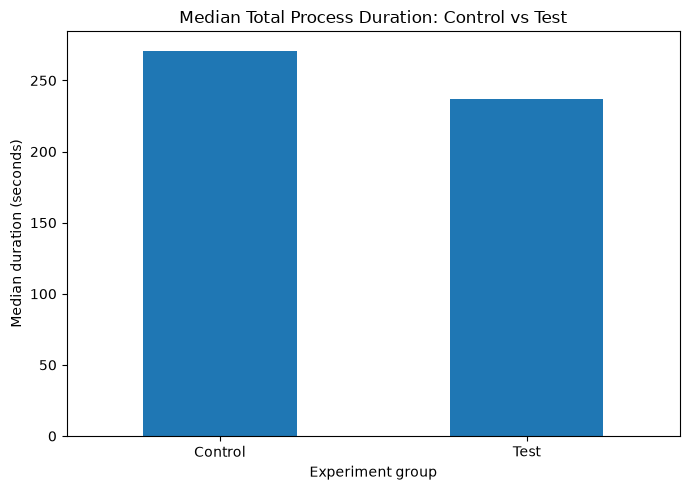

In [48]:
# Compare median total duration for completed visits
duration_comparison["median"].plot(
    kind="bar",
    figsize=(7, 5),
    ylabel="Median duration (seconds)",
    xlabel="Experiment group",
    title="Median Total Process Duration: Control vs Test",
)

# Display the chart with readable labels
plt.xticks(rotation=0)
plt.tight_layout()

### Findings: Time-Based KPIs

The new design showed a lower median total process duration than the old design: 3 minutes and 57 seconds compared with 4 minutes and 31 seconds. This is a reduction of 34 seconds, or approximately 12.5%.

When comparing individual process steps, the new design had lower median elapsed times at `start`, `step_2` and `step_3`. However, the median time at `step_1` was 7 seconds higher than in the old design, suggesting that this step may need further investigation.

Overall, the descriptive results suggest that clients who completed the process using the new design generally did so faster. However, these results alone do not establish statistical significance or prove that the redesign caused the improvement. Total process duration was calculated only for completed visits, and the measured time represents elapsed time rather than active interaction time.

## 2.5 Hypothesis Test: Time at `step_1` by Age Group

**Objective**

To investigate whether the time between `step_1` and the next recorded event differs across age groups.

**Approach**

We will identify the age information available in the demographic dataset, combine it with our time-based data, and compare the time intervals across age groups. We will then perform a statistical hypothesis test to determine whether the differences are statistically significant.

### Calculate Time After `step_1`

We will sort website events by client, visit, and timestamp. Then, we will calculate the time between each event and the next recorded event. This allows us to isolate the time intervals following `step_1`.

In [41]:
# Copy the cleaned website activity data and sort events chronologically
df_age_time = df.sort_values(by=["client_id", "visit_id", "date_time"]).copy()

# Get the timestamp of the next event within each client visit
df_age_time["next_date_time"] = df_age_time.groupby(["client_id", "visit_id"])[
    "date_time"
].shift(-1)

# Calculate the time between the current event and the next event in seconds
df_age_time["time_seconds"] = (
    df_age_time["next_date_time"] - df_age_time["date_time"]
).dt.total_seconds()

# Keep only step_1 events that have a following event
step1_age = df_age_time[
    (df_age_time["process_step"] == "step_1") & (df_age_time["next_date_time"].notna())
].copy()

# Display a sample to check the results
display(
    step1_age[
        [
            "client_id",
            "visit_id",
            "Variation",
            "process_step",
            "date_time",
            "next_date_time",
            "time_seconds",
        ]
    ].head()
)

,client_id,visit_id,Variation,process_step,date_time,next_date_time,time_seconds
70439,555,637149525_38041617439_716659,Test,step_1,2017-04-15 12:58:03,2017-04-15 12:58:35,32.0
135230,647,40369564_40101682850_311847,Test,step_1,2017-04-12 15:41:35,2017-04-12 15:41:53,18.0
129573,1028,557292053_87239438319_391157,Control,step_1,2017-04-08 18:52:17,2017-04-08 18:53:20,63.0
129572,1028,557292053_87239438319_391157,Control,step_1,2017-04-08 18:53:20,2017-04-08 18:53:29,9.0
129569,1028,557292053_87239438319_391157,Control,step_1,2017-04-08 18:59:55,2017-04-08 19:00:15,20.0


### Add Client Age Groups

We will merge the client demographics into the time-interval data using `client_id`. Then, we will group clients by age to compare the time spent after `step_1`.

In [ ]:
# Add client age to each step_1 time interval using client_id
step1_age = step1_age.merge(
    clients[["client_id", "clnt_age"]], on="client_id", how="left"
)

# Check that age information was successfully added
print("Missing ages:", step1_age["clnt_age"].isna().sum())

# Display the time intervals with client age
display(step1_age[["client_id", "Variation", "clnt_age", "time_seconds"]].head())

Missing ages: 24


,client_id,Variation,clnt_age,time_seconds
0,555,Test,29.5,32.0
1,647,Test,57.5,18.0
2,1028,Control,36.0,63.0
3,1028,Control,36.0,9.0
4,1028,Control,36.0,20.0


### Create Age Groups

We will divide clients into three age groups: 18–39, 40–59, and 60+. This will allow us to compare the time spent after `step_1` across different age groups.

In [43]:
# Remove intervals without age information
step1_age = step1_age.dropna(subset=["clnt_age"]).copy()

# Assign each client to an age group
step1_age["age_group"] = pd.cut(
    step1_age["clnt_age"],
    bins=[0, 39, 59, float("inf")],
    labels=["18–39", "40–59", "60+"],
)

# Count the intervals in each age group
print(step1_age["age_group"].value_counts().sort_index())

age_group
18–39    20189
40–59    23993
60+      17364
Name: count, dtype: int64


### Compare Time Across Age Groups

We will calculate the mean and median time between `step_1` and the next recorded event for each age group. This will help us identify possible differences before performing a statistical hypothesis test.

In [44]:
# Compare the time intervals across age groups using summary statistics
age_time_summary = (
    step1_age.groupby("age_group", observed=True)["time_seconds"]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the results in seconds
display(age_time_summary)

,count,mean,median
age_group,,,
18–39,20189,42.4,16.0
40–59,23993,56.2,25.0
60+,17364,72.9,35.0


### Hypothesis Testing

**Research question**

Does the time between `step_1` and the next recorded event differ across age groups?

**Null hypothesis (H0):** The distribution of time intervals is the same across the three age groups.

**Alternative hypothesis (H1):** At least one age group has a different distribution of time intervals.

We will use the Kruskal–Wallis test with a significance level of 0.05.

In [ ]:
# Separate the time intervals into the three age groups
time_18_39 = step1_age.loc[step1_age["age_group"] == "18–39", "time_seconds"]

time_40_59 = step1_age.loc[step1_age["age_group"] == "40–59", "time_seconds"]

time_60_plus = step1_age.loc[step1_age["age_group"] == "60+", "time_seconds"]

# Test whether the time distributions differ across age groups
statistic, p_value = kruskal(time_18_39, time_40_59, time_60_plus)

# Display the test results
print("Kruskal-Wallis statistic:", round(statistic, 3))
print("P-value:", p_value)

Kruskal-Wallis statistic: 3471.439
P-value: 0.0


### Visualization: Time After `step_1` by Age Group

This chart compares the median elapsed time after `step_1` across the three age groups.

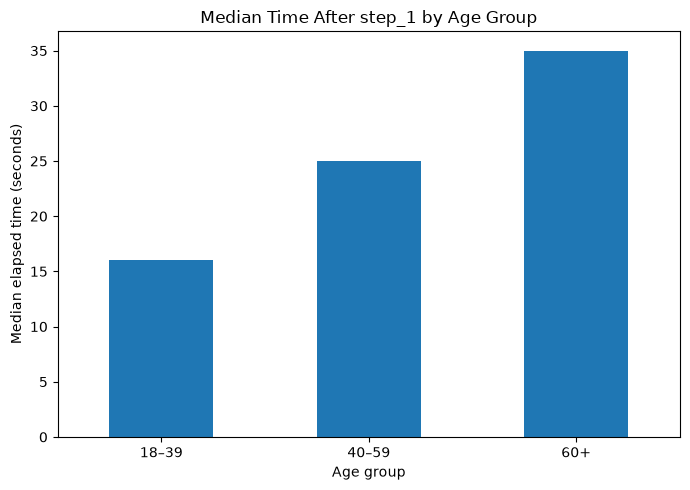

In [ ]:
# Plot the median time after step_1 for each age group
age_time_summary["median"].plot(
    kind="bar",
    figsize=(7, 5),
    ylabel="Median elapsed time (seconds)",
    xlabel="Age group",
    title="Median Time After step_1 by Age Group",
)

# Keep the labels horizontal and adjust the chart layout
plt.xticks(rotation=0)
plt.tight_layout()

### Hypothesis Test Results

The Kruskal–Wallis test returned a statistic of 3471.439 and a p-value smaller than 0.05.

Therefore, we reject the null hypothesis. There is statistically significant evidence that the time between `step_1` and the next recorded event differs across age groups.

The median time increased with age: 16 seconds for clients aged 18–39, 25 seconds for clients aged 40–59, and 35 seconds for clients aged 60+.

These results suggest an association between age group and time spent after `step_1`. However, the test does not establish which specific age groups differ significantly, nor does it show that age causes longer completion times. Some clients also contribute multiple intervals, which limits the independence of the observations.